# 03 · ERA5 weather features: sanity checks

Built by `python -m glg.build.weather` (ERA5 → county × hour → BA × hour) and checked by
`python -m glg.build.weather_check`. Method in DATA.md, "Weather features".

1. ERA5 county temperature against NOAA ISD airport stations (Dulles/DOM, Phoenix/SRP+AZPS,
   DFW/ERCO, Miami/FPL): a summer week, and the bias year by year (is there drift?).
2. Phoenix: Sky Harbor against seven other Phoenix-area airports.
3. Load vs temperature for the same BAs: does demand respond to BA temperature as physics says?
4. How much the BA → county mapping choice moves BA temperature.

In [1]:
import matplotlib.pyplot as plt
import polars as pl
from datetime import datetime, UTC
from glg.build import weather as w, weather_check as wc
from glg.ingest import isd

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e5e5e5", "grid.linewidth": 0.6, "font.size": 9})
INK, MUTED = "#1f2937", "#6b7280"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]  # dataviz categorical slots 1-4
check = pl.read_csv(wc.STATION_CHECK_PATH, schema_overrides={"station": pl.Utf8})
sens = pl.read_csv(wc.SENSITIVITY_PATH)
weather = pl.read_parquet(w.OUT_PATH)

## 1. ERA5 county vs airport, a summer week (2024-07-15 → 22, UTC)

/var/folders/1b/qt3mr0d51kx01__c48xxtw9w0000gn/T/ipykernel_18192/3942252457.py:14: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  fig.autofmt_xdate()


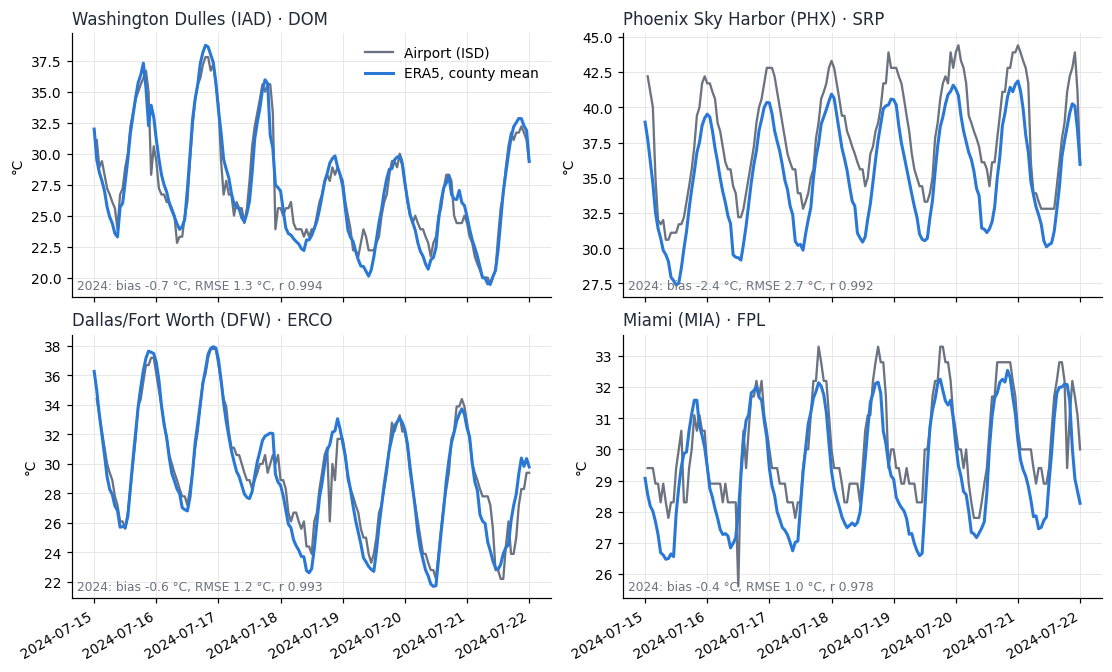

In [2]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True, layout="constrained")
t0, t1 = datetime(2024, 7, 15, tzinfo=UTC), datetime(2024, 7, 22, tzinfo=UTC)
for ax, (s, (name, ba, fips)) in zip(axes.flat, isd.STATIONS.items()):
    st = isd.read_hourly(s, 2024).filter(pl.col("time_utc").is_between(t0, t1))
    c = wc.county_series(fips).filter(pl.col("valid_time_utc").is_between(t0, t1))
    ax.plot(st["time_utc"], st["tmp_c"], color=MUTED, lw=1.5, label="Airport (ISD)")
    ax.plot(c["valid_time_utc"], c["t2m_c"], color=SERIES[0], lw=2, label="ERA5, county mean")
    r = check.filter(pl.col("station") == s, pl.col("year") == 2024).row(0, named=True)
    ax.set_title(f"{name} · {ba}", loc="left", color=INK)
    ax.text(0.01, 0.03, f"2024: bias {r['bias_c']:+.1f} °C, RMSE {r['rmse_c']:.1f} °C, r {r['r']:.3f}",
            transform=ax.transAxes, color=MUTED, fontsize=8)
    ax.set_ylabel("°C")
axes[0, 0].legend(loc="upper right", frameon=False)
fig.autofmt_xdate()
fig.savefig("../report/figures/weather_station_week.png", dpi=110, bbox_inches="tight")

ERA5's county mean follows the airport hour by hour. It is smoother at the peaks: it's a
0.25° average over a whole county, not a point on a runway. Miami's afternoon peaks are cut
most, because some of the coastal cells are partly sea.

## 2. Does the ERA5 – station gap drift? (annual mean bias, °C)

airport,2016-19,2023-25,shift_c
str,f64,f64,f64
"""Luke AFB (LUF)""",-0.27475,-0.961,-0.69
"""Phoenix Sky Harbor (PHX)""",-1.60775,-2.227333,-0.62
"""Mesa Gateway (IWA)""",0.587,0.151,-0.44
"""Washington Dulles (IAD)""",0.12475,-0.289333,-0.41
"""Goodyear (GYR)""",-0.37725,-0.65,-0.27
"""Chandler (CHD)""",-0.3085,-0.424667,-0.12
"""Scottsdale (SDL)""",-0.56075,-0.632,-0.07
"""Miami (MIA)""",-0.541,-0.525667,0.02
"""Dallas/Fort Worth (DFW)""",-0.46775,-0.347333,0.12


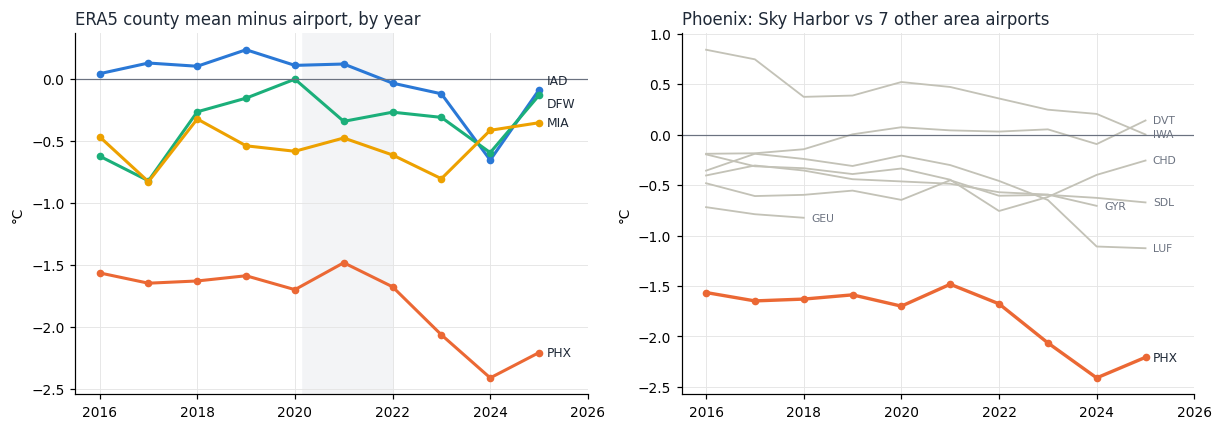

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
ax = axes[0]
for i, (s, (name, ba, _)) in enumerate(isd.STATIONS.items()):
    d = check.filter(pl.col("station") == s).sort("year")
    ax.plot(d["year"], d["bias_c"], color=SERIES[i], lw=2, marker="o", ms=4)
    code = name.split("(")[1][:3]
    nudge = {"IAD": 0.07, "DFW": -0.07}.get(code, 0)  # 2025 values nearly coincide
    ax.text(d["year"][-1] + 0.15, d["bias_c"][-1] + nudge, code, color=INK, va="center", fontsize=8)
ax.axhline(0, color=MUTED, lw=0.8)
ax.axvspan(2020 + 2/12, 2022, color="#f3f4f6", zorder=0)
ax.set_title("ERA5 county mean minus airport, by year", loc="left", color=INK)
ax.set_ylabel("°C"); ax.set_xlim(2015.5, 2026)
ax = axes[1]
for s, name in isd.PHOENIX_CHECK.items():
    d = check.filter(pl.col("station") == s).sort("year")
    ax.plot(d["year"], d["bias_c"], color="#c3c2b7", lw=1.2)
    ax.text(d["year"][-1] + 0.15, d["bias_c"][-1], name.split("(")[1][:3], color=MUTED, va="center", fontsize=7)
d = check.filter(pl.col("station") == "72278023183").sort("year")
ax.plot(d["year"], d["bias_c"], color=SERIES[1], lw=2.2, marker="o", ms=4)
ax.text(d["year"][-1] + 0.15, d["bias_c"][-1], "PHX", color=INK, va="center", fontsize=8)
ax.axhline(0, color=MUTED, lw=0.8)
ax.set_title("Phoenix: Sky Harbor vs 7 other area airports", loc="left", color=INK)
ax.set_ylabel("°C"); ax.set_xlim(2015.5, 2026)
fig.savefig("../report/figures/weather_station_drift.png", dpi=110, bbox_inches="tight")
shift = (check.with_columns(pl.when(pl.col("year") <= 2019).then(pl.lit("2016-19"))
                            .when(pl.col("year") >= 2023).then(pl.lit("2023-25")).alias("p"))
         .drop_nulls("p").group_by("airport", "p").agg(pl.col("bias_c").mean())
         .pivot(on="p", index="airport", values="bias_c").drop_nulls()
         .with_columns((pl.col("2023-25") - pl.col("2016-19")).round(2).alias("shift_c")).sort("shift_c"))
shift

- Dulles, DFW and Miami: no step between the baseline and 2023–25. Dulles 2024 is a one-year dip
  that reverses in 2025.
- Phoenix: Sky Harbor's gap widens by about 0.6 °C from 2023, and Luke AFB's by about 0.7 °C. The
  other five airports move between −0.4 and +0.2 °C, and the median of the eight is about −0.3 °C.
  Most of Sky Harbor's step is local to that station (runway or urban heat island), but ERA5 may
  under-capture about 0.3 °C of recent warming across Phoenix. If so, the weather model will
  slightly under-predict Phoenix cooling load after 2022, and some of that will show up as
  "structural growth" in AZPS and SRP. **Prompt 15 must re-run AZPS/SRP with ERA5 + 0.3 °C after
  2022 (or with station temperature) and report how much the growth estimate moves.**

## 3. Load vs BA temperature (2019, hourly)

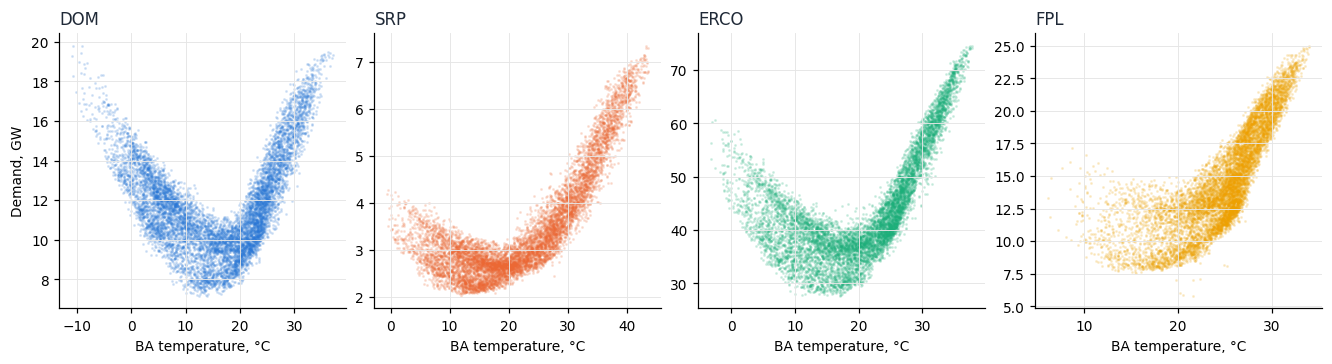

In [4]:
dem = pl.read_parquet(w.PROCESSED_DIR / "demand_clean.parquet", columns=["ba", "period_end_utc", "demand_clean"])
dom = (pl.read_parquet(w.PROCESSED_DIR / "subregion_demand_clean.parquet", columns=["subregion", "period_end_utc", "demand_clean"])
       .filter(pl.col("subregion") == "DOM").rename({"subregion": "ba"}))  # DOM is a PJM subregion in EIA-930
dem = pl.concat([dem.with_columns(pl.col("period_end_utc").dt.cast_time_unit("us")),
                 dom.with_columns(pl.col("period_end_utc").dt.cast_time_unit("us"))])
fig, axes = plt.subplots(1, 4, figsize=(12, 3.2), layout="constrained")
for i, (ax, ba) in enumerate(zip(axes, ["DOM", "SRP", "ERCO", "FPL"])):
    j = (dem.filter(pl.col("ba") == ba, pl.col("period_end_utc").dt.year() == 2019)
         .join(weather.filter(pl.col("ba") == ba), on=["ba", "period_end_utc"]).drop_nulls("demand_clean"))
    ax.scatter(j["t2m_c"], j["demand_clean"] / 1000, s=1, alpha=0.15, color=SERIES[i], rasterized=True)
    ax.set_title(ba, loc="left", color=INK); ax.set_xlabel("BA temperature, °C")
axes[0].set_ylabel("Demand, GW")
fig.savefig("../report/figures/weather_load_vs_temp.png", dpi=110, bbox_inches="tight")

Each BA shows the expected shape: a heating arm where winters are cold (DOM; ERCO a little), a
steep cooling arm above about 18–20 °C, and the widest spread at a given temperature coming from
hour of day and day type (Prompt 6's calendar features).

## 4. Mapping sensitivity: raked weights vs whole-county weights

In [5]:
with pl.Config(tbl_rows=50):
    display(sens.select("ba", "year", "mean_diff_c", "rms_diff_c", "r", "cdh65f_diff_pct").sort("rms_diff_c", descending=True))

ba,year,mean_diff_c,rms_diff_c,r,cdh65f_diff_pct
str,i64,f64,f64,f64,f64
"""GCPD""",2024,-1.215,1.319,0.999,-17.380847
"""GCPD""",2019,-1.091,1.297,0.999,-21.117488
"""MISO""",2019,1.096,1.231,0.999,15.959032
"""MISO""",2024,0.828,0.922,0.999,13.282273
"""NEVP""",2024,-0.711,0.832,0.999,-8.595158
"""NEVP""",2019,-0.651,0.779,0.999,-9.082272
"""FPL""",2019,-0.488,0.692,0.997,-4.777965
"""SWPP""",2024,-0.547,0.675,0.999,-4.489914
"""FPL""",2024,-0.489,0.662,0.998,-4.796844


The crude alternative counts every county a BA touches in full. Even so, the hourly correlation
with the main series is ≥ 0.997 for every shortlisted BA. The largest level offsets (GCPD about
−1.2 °C, MISO about +1 °C) are nearly the same in 2019 and 2024. A per-BA model absorbs a constant
offset, so the mapping weaknesses (slivers; DATA.md) can't create a trend in the weather series.